# 02. Métricas y cronometrado

Para comparar dos métodos necesitamos medir dos cosas: **qué tan bien** restauran y **cuánto tardan**. Este cuaderno prueba las funciones de `src/metricas.py`.

## Las fórmulas

Comparamos la imagen original sana $I_1$ con la restaurada $I_2$ (artículo base, apartado IV, ecuaciones (1) y (2) \[4\]):

$$\mathrm{MSE}=\frac{1}{M\,N}\sum_{m,n}\bigl[I_1(m,n)-I_2(m,n)\bigr]^2\qquad\qquad \mathrm{PSNR}=10\log_{10}\frac{R^2}{\mathrm{MSE}}$$

- **MSE** (error cuadrático medio): la media de los errores al cuadrado. Vale 0 si las imágenes son iguales.
- **PSNR** (relación señal-ruido de pico, en dB): cuanto más alto, menos error. $R$ es el valor máximo de un píxel, 255 en imágenes de 8 bits.

Las dos se pueden calcular sobre **toda la imagen** o **solo sobre el hueco**. Sobre toda la imagen, los píxeles que no se tocaron tienen error 0 y bajan el MSE; sobre el hueco se mide solo lo que el algoritmo ha tenido que rellenar.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

import mascaras as m
import metricas as k

## 1. Comprobaciones a mano

Antes de usarlas con fotos, probamos las funciones con casos pequeños en los que el resultado se puede calcular con lápiz y papel.

### Un ejemplo de 2×2

Original `[[10, 20], [30, 40]]` y restaurada `[[12, 20], [30, 36]]`. Los errores son 2, 0, 0 y −4; al cuadrado, 4, 0, 0 y 16, que suman 20. El MSE es $20/4=5$ y el PSNR es $10\log_{10}(255^2/5)\approx 41{,}14$ dB.

In [2]:
original = np.array([[10, 20], [30, 40]], dtype=np.uint8)
restaurada = np.array([[12, 20], [30, 36]], dtype=np.uint8)

print("MSE :", k.mse(original, restaurada), "(a mano: 5)")
print("PSNR:", round(k.psnr(original, restaurada), 2), "dB (a mano: 41.14)")
assert k.mse(original, restaurada) == 5
assert abs(k.psnr(original, restaurada) - 41.14) < 0.01

MSE : 5.0 (a mano: 5)
PSNR: 41.14 dB (a mano: 41.14)


### Imágenes iguales

El error es 0, y el PSNR divide entre 0: la función devuelve infinito.

In [3]:
print("MSE :", k.mse(original, original))
print("PSNR:", k.psnr(original, original))
assert k.mse(original, original) == 0
assert k.psnr(original, original) == float("inf")

MSE : 0.0
PSNR: inf


### Un error constante

Si todos los píxeles se desvían exactamente 10, el MSE es $10^2=100$ y el PSNR es $10\log_{10}(255^2/100)\approx 28{,}13$ dB.

In [4]:
gris = np.full((50, 50), 100, dtype=np.uint8)
print("MSE :", k.mse(gris, gris + 10), "(a mano: 100)")
print("PSNR:", round(k.psnr(gris, gris + 10), 2), "dB (a mano: 28.13)")
assert k.mse(gris, gris + 10) == 100
assert abs(k.psnr(gris, gris + 10) - 28.13) < 0.01

MSE : 100.0 (a mano: 100)
PSNR: 28.13 dB (a mano: 28.13)


### Un fallo típico: restar enteros de 8 bits

Las imágenes son de tipo `uint8`, números enteros de 0 a 255. Si se restan directamente, el resultado «da la vuelta»: `50 - 200` no da −150 sino 106. Y al elevar al cuadrado vuelve a desbordarse. Por eso `mse` convierte las imágenes a decimales antes de restar. Comparamos con la cuenta ingenua:

In [5]:
a = np.array([[200]], dtype=np.uint8)
b = np.array([[50]], dtype=np.uint8)

ingenuo = ((a - b) ** 2).mean()
print("Cuenta ingenua con uint8:", ingenuo)
print("Con la función           :", k.mse(a, b), "(a mano: 150 al cuadrado = 22500)")
assert k.mse(a, b) == 22500

Cuenta ingenua con uint8: 228.0
Con la función           : 22500.0 (a mano: 150 al cuadrado = 22500)


### Medir solo el hueco o la imagen entera

Si el error es `e` en el hueco y 0 fuera, el MSE de la imagen entera es el del hueco multiplicado por la fracción de imagen que ocupa el hueco. Con un hueco del 10 % y error 10, el MSE del hueco es 100 y el de la imagen, 10.

In [6]:
mascara = np.zeros((10, 10), dtype=bool)
mascara[:2, :5] = True                       # 10 píxeles de 100: el 10 %

sana = np.full((10, 10), 100, dtype=np.uint8)
con_error = sana.copy()
con_error[mascara] = 110

print("MSE del hueco :", k.mse(sana, con_error, mascara))
print("MSE de la imagen:", k.mse(sana, con_error))
assert k.mse(sana, con_error, mascara) == 100
assert k.mse(sana, con_error) == 10

MSE del hueco : 100.0
MSE de la imagen: 10.0


## 2. Con una foto real

Estropeamos una foto con una máscara de `mascaras.py` y la «restauramos» de la forma más simple posible, rellenando el hueco con el color medio del resto de la imagen. No es un método de verdad: solo sirve para ver cómo cambian las métricas.

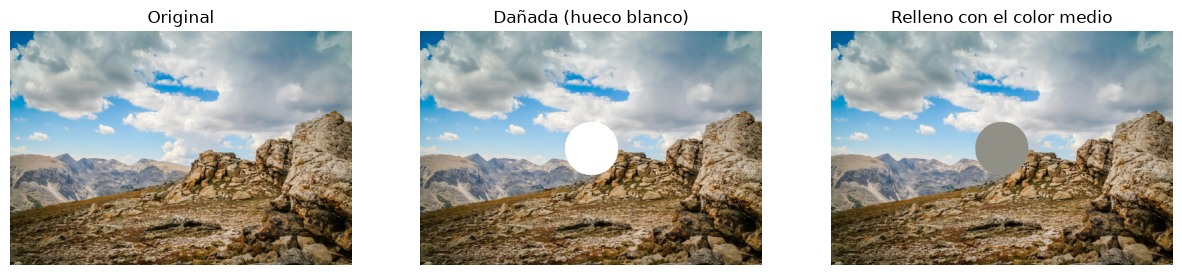

dañada          MSE hueco    4195.7   PSNR hueco  11.90 dB   MSE imagen   117.65   PSNR imagen  27.42 dB
relleno simple  MSE hueco    4810.0   PSNR hueco  11.31 dB   MSE imagen   134.88   PSNR imagen  26.83 dB


In [7]:
imagen = cv.imread("../images/originales/photo-1431315906474-0e7a186c0304.jpg")
imagen = cv.cvtColor(imagen, cv.COLOR_BGR2RGB)
escala = 512 / max(imagen.shape[:2])
imagen = cv.resize(imagen, (round(imagen.shape[1] * escala), round(imagen.shape[0] * escala)), interpolation=cv.INTER_AREA)

mascara = m.mascara_circular(imagen.shape[:2], 40)
danada = m.aplicar_mascara(imagen, mascara)

# Relleno simple: el color medio de los píxeles buenos, en cada canal.
simple = danada.copy()
simple[mascara] = imagen[~mascara].mean(axis=0).round().astype(np.uint8)

plt.figure(figsize=(15, 4.5))
for k_, (titulo, im) in enumerate([("Original", imagen), ("Dañada (hueco blanco)", danada), ("Relleno con el color medio", simple)]):
    plt.subplot(1, 3, k_ + 1)
    plt.imshow(im)
    plt.title(titulo)
    plt.axis("off")
plt.show()

for nombre, im in [("dañada", danada), ("relleno simple", simple)]:
    r = k.evaluar(imagen, im, mascara)
    print(f"{nombre:15s} MSE hueco {r['mse_hueco']:9.1f}   PSNR hueco {r['psnr_hueco']:6.2f} dB   MSE imagen {r['mse_imagen']:8.2f}   PSNR imagen {r['psnr_imagen']:6.2f} dB")

Dos cosas que se ven en los números:

- **El relleno simple no mejora al hueco blanco**: el error del hueco es incluso algo mayor (4810 frente a 4196). Lo que había dentro del hueco era, de media, bastante claro (un valor de unos 200), y está más cerca del blanco (255) que del color medio de toda la foto (unos 143). Un relleno sin criterio no tiene por qué mejorar nada, y por eso hay que medir siempre y no fiarse del aspecto.
- **Medir el hueco o la imagen entera da cifras muy distintas.** Con la imagen entera el PSNR sale mucho más alto (27 dB frente a 12 dB), porque la mayoría de los píxeles no se han tocado y tienen error 0. **Para comparar métodos conviene mirar sobre todo el hueco**, y dar también el de la imagen entera, que es el de las fórmulas del artículo.

## 3. Cronometrar

El tiempo de una ejecución varía de una vez a otra (otros programas, la caché del procesador…). Por eso `cronometrar` repite la función varias veces y devuelve la media y todos los tiempos.

De ejemplo medimos una función cualquiera: 100 pasos de sumar los cuatro vecinos de cada píxel.

In [8]:
def ejemplo(imagen):
    A = imagen.astype(np.float64)
    for _ in range(100):
        A = (np.roll(A, 1, 0) + np.roll(A, -1, 0) + np.roll(A, 1, 1) + np.roll(A, -1, 1)) / 4
    return A

resultado, media, tiempos = k.cronometrar(ejemplo, imagen, repeticiones=5)

print("Tiempos de cada ejecución (s):", [round(t, 4) for t in tiempos])
print(f"Media: {media:.4f} s   Mínimo: {min(tiempos):.4f} s   Máximo: {max(tiempos):.4f} s")
assert len(tiempos) == 5
assert abs(media - np.mean(tiempos)) < 1e-12

Tiempos de cada ejecución (s): [0.126, 0.129, 0.1262, 0.1253, 0.1289]
Media: 0.1271 s   Mínimo: 0.1253 s   Máximo: 0.1290 s


## 4. El equipo

Un tiempo solo se puede comparar con otro si se sabe en qué máquina se midió. `informacion_equipo` recoge los datos para anotarlos junto a los resultados.

In [9]:
for dato, valor in k.informacion_equipo().items():
    print(f"{dato:12s} {valor}")

sistema      macOS-27.0.1-arm64-arm-64bit-Mach-O
procesador   arm
nucleos      10
memoria_gb   17.2
python       3.14.6
numpy        2.5.4
opencv       5.0.0


## Resumen

- `mse` y `psnr` miden el error entre la imagen original y la restaurada, sobre el hueco (con máscara) o sobre la imagen entera (sin ella). `evaluar` da las cuatro cifras juntas.
- Las comprobaciones a mano coinciden: el ejemplo de 2×2 da MSE 5 y PSNR 41,14 dB, el error constante de 10 da MSE 100 y 28,13 dB, y las imágenes iguales dan MSE 0 y PSNR infinito.
- `mse` convierte a decimales antes de restar, para evitar el desbordamiento de `uint8`.
- `cronometrar` repite la medida y `informacion_equipo` anota la máquina.
- Siguiente paso: `src/difusion.py`, con la difusión simple (la media de los cuatro vecinos).